In [ ]:
import numpy as np
import pandas as pd
from pyswarm import pso
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor

# Load the data
input_csv = "/Users/kshitijsharma/Old Documents/College/Surbhi ma'am work/Final work/Feature Extraction/combined_features.csv"
data = pd.read_csv(input_csv)

# Extract features and labels
X = np.array([eval(row) for row in data['Combined_Features']])
y = data['Class_Label']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define fitness function
def fitness_function(mask):
    selected_features = X_train[:, mask > 0.5]
    test_features = X_test[:, mask > 0.5]
    
    if selected_features.shape[1] == 0:
        return 1  # Avoid no-feature selections
    
    model = RandomForestClassifier()
    model.fit(selected_features, y_train)
    predictions = model.predict(test_features)
    accuracy = accuracy_score(y_test, predictions)
    
    # We aim to maximize accuracy, so return 1 - accuracy
    return 1 - accuracy

# Parallel wrapper for the fitness function
def parallel_fitness(masks):
    with ThreadPoolExecuAGtor() as executor:
        results = list(executor.map(fitness_function, masks))
    return results

# Run PSO to optimize feature selection
num_features = X.shape[1]

lb = [0] * num_features
ub = [1] * num_features

# Improved progress tracking
swarmsize = 20
maxiter = 100

print("Running Particle Swarm Optimization with parallel processing...")
progress_bar = tqdm(total=maxiter * swarmsize, desc='PSO Progress', position=0, leave=True)

iteration_counter = 0

def wrapped_fitness(mask):
    global iteration_counter
    iteration_counter += 1
    progress_bar.update(1)
    return fitness_function(mask)

best_mask, _ = pso(wrapped_fitness, lb, ub, swarmsize=swarmsize, maxiter=maxiter)

progress_bar.close()

# Convert mask to boolean
selected_features_idx = np.where(best_mask > 0.5)[0]

# Create new DataFrame with selected features
new_features = [str(list(X[i, selected_features_idx])) for i in range(len(X))]
output_data = pd.DataFrame({
    'Image_Index': data['Image_Index'],
    'Class_Label': y,
    'Selected_Features': new_features
})

# Save the new CSV
output_csv = 'PSO_selected_features.csv'
output_data.to_csv(output_csv, index=False)

print(f"New CSV saved as {output_csv} with {len(selected_features_idx)} selected features.")

Running Particle Swarm Optimization with parallel processing...


PSO Progress: 2020it [11:09,  3.02it/s]                          

Stopping search: maximum iterations reached --> 100
New CSV saved as PSO_selected_features.csv with 106 selected features.


In [4]:
import pandas as pd

# Load the original and new CSVs
original_csv = pd.read_csv("/Users/kshitijsharma/Old Documents/College/Surbhi ma'am work/Final work/Feature Extraction/combined_features.csv")
selected_csv = pd.read_csv("/Users/kshitijsharma/Old Documents/College/Surbhi ma'am work/Final work/Metaheuristic Algorithms/PSO_selected_features.csv")

# Extract feature counts
original_features_count = len(eval(original_csv['Combined_Features'][0]))
selected_features_count = len(eval(selected_csv['Selected_Features'][0]))

# Compare feature counts
print(f"Original number of features: {original_features_count}")
print(f"Number of selected features: {selected_features_count}")
print(f"Reduction percentage: {100 * (1 - selected_features_count / original_features_count):.2f}%")


Original number of features: 199
Number of selected features: 106
Reduction percentage: 46.73%


# ML techniques and their metrics

In [1]:
import pandas as pd

df = pd.read_csv('PSO_selected_features.csv')
df['Selected_Features'][0]

'[np.float64(-0.9011194286552345), np.float64(-0.7975658463525188), np.float64(-0.754533970796162), np.float64(-0.6728060701773021), np.float64(0.08672116376885615), np.float64(-0.17624767226321517), np.float64(-0.21604795912780475), np.float64(-0.22950895492546589), np.float64(0.18824083044414577), np.float64(0.1297863540994063), np.float64(-0.01625979767982814), np.float64(0.0764390885350201), np.float64(-0.354911197873462), np.float64(-0.8795250450439783), np.float64(-0.754533970796162), np.float64(-0.6728060701773021), np.float64(-0.0803936562124509), np.float64(-0.06036978037799432), np.float64(-0.09994881100184021), np.float64(-0.2276036533876782), np.float64(-0.21604795912780475), np.float64(0.1297863540994063), np.float64(0.0764390885350201), np.float64(-0.34884175048679955), np.float64(-0.3474210133140654), np.float64(-0.8605132988601341), np.float64(0.09439881256825286), np.float64(-0.03922711142637699), np.float64(-1.268589315265351), np.float64(-0.33324549341691034), np.flo

In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, Flatten, MaxPooling1D, Dropout
import matplotlib.pyplot as plt
import seaborn as sns

# Load CSV
data = pd.read_csv("/Users/kshitijsharma/Old Documents/College/Surbhi ma'am work/Final work/Metaheuristic Algorithms/PSO_selected_features.csv")

# Parse features
features = data['Selected_Features'].apply(lambda x: np.array(eval(x))).tolist()
X = np.array(features)
y = data['Class_Label']

# Encode class labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Helper function to evaluate models
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, average='weighted'))
    print("Recall:", recall_score(y_test, y_pred, average='weighted'))
    print("F1 Score:", f1_score(y_test, y_pred, average='weighted'))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d')
    plt.show()

Accuracy: 0.8134715025906736
Precision: 0.8197958665331416
Recall: 0.8134715025906736
F1 Score: 0.8118640828878522
Confusion Matrix:
 [[33  2  2  0  3  0]
 [ 1 23  0  0  3  0]
 [10  0 21  1  1  0]
 [ 0  0  0 33  0  0]
 [ 1  0  1  0 20  8]
 [ 0  0  0  0  3 27]]


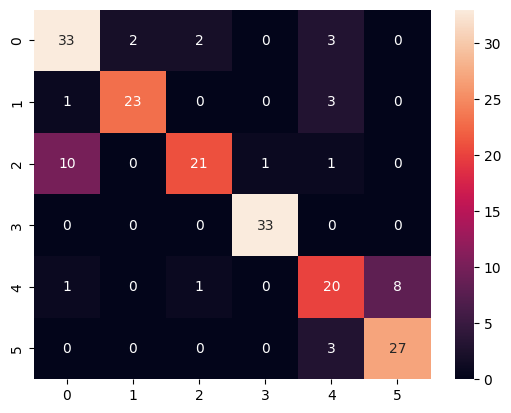

In [12]:
# 1. Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
evaluate_model(nb_model, X_test, y_test)

Accuracy: 0.9326424870466321
Precision: 0.9348805878922459
Recall: 0.9326424870466321
F1 Score: 0.9328941869584287
Confusion Matrix:
 [[38  0  2  0  0  0]
 [ 0 25  1  0  1  0]
 [ 4  0 28  1  0  0]
 [ 0  0  2 31  0  0]
 [ 0  0  0  0 30  0]
 [ 0  0  0  0  2 28]]


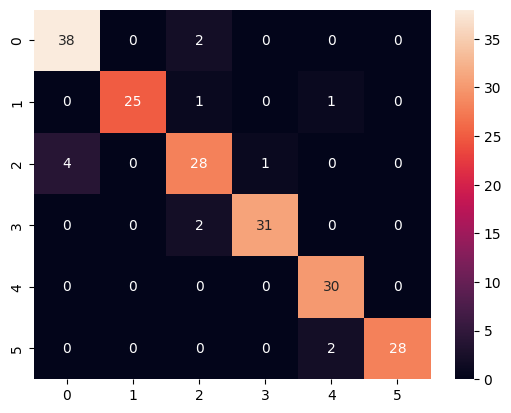

In [13]:
# 2. Support Vector Machine
svm_model = SVC()
svm_model.fit(X_train, y_train)
evaluate_model(svm_model, X_test, y_test)

Accuracy: 0.844559585492228
Precision: 0.8498827379329152
Recall: 0.844559585492228
F1 Score: 0.846047856155132
Confusion Matrix:
 [[33  1  4  0  1  1]
 [ 2 21  2  0  1  1]
 [ 3  2 27  1  0  0]
 [ 1  0  3 29  0  0]
 [ 1  1  1  0 26  1]
 [ 0  0  1  0  2 27]]


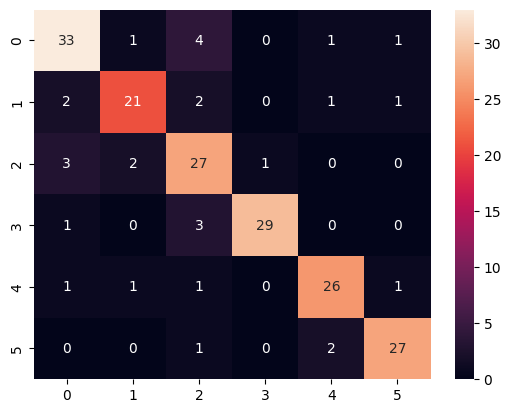

In [14]:
# 3. Decision Tree
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train)
evaluate_model(dt_model, X_test, y_test)

Accuracy: 0.927461139896373
Precision: 0.9278095980905521
Recall: 0.927461139896373
F1 Score: 0.927411905067648
Confusion Matrix:
 [[37  1  1  0  0  1]
 [ 0 26  0  0  1  0]
 [ 2  0 29  2  0  0]
 [ 0  0  2 31  0  0]
 [ 0  0  1  0 27  2]
 [ 0  0  0  0  1 29]]


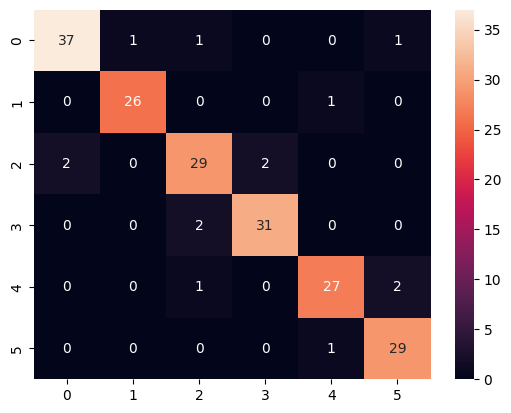

In [15]:
# 4. Random Forest
rf_model = RandomForestClassifier()
rf_model.fit(X_train, y_train)
evaluate_model(rf_model, X_test, y_test)

/Users/kshitijsharma/ml_envs/tensorflow-gpu/lib/python3.10/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9203 - loss: 0.2274  
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Accuracy: 0.9326424870466321
Precision: 0.9354527723185039
Recall: 0.9326424870466321
F1 Score: 0.9332347321877593
Confusion Matrix:
 [[38  0  2  0  0  0]
 [ 0 25  1  0  1  0]
 [ 0  0 32  1  0  0]
 [ 0  0  1 32  0  0]
 [ 0  0  0  0 27  3]
 [ 0  0  0  0  4 26]]


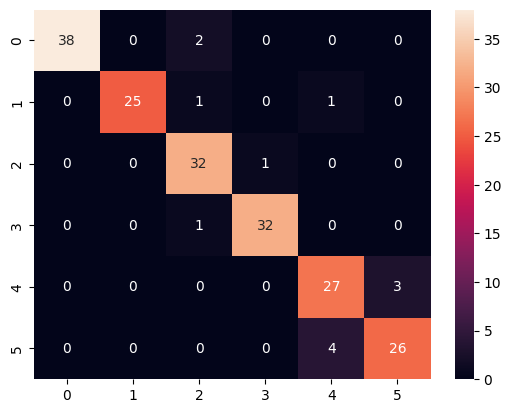

In [ ]:
# 5. Artificial Neural Network

def evaluate_model(model, X_test, y_test, labels=None):
    # Handle ANN/CNN differently — check if output is probabilistic
    y_pred = model.predict(X_test)
    if len(y_pred.shape) > 1 and y_pred.shape[1] > 1:
        y_pred = np.argmax(y_pred, axis=1)  # Convert softmax output to class labels
    
    # Compute metrics
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, average='weighted', zero_division=0))
    print("Recall:", recall_score(y_test, y_pred, average='weighted', zero_division=0))
    print("F1 Score:", f1_score(y_test, y_pred, average='weighted', zero_division=0))
    
    # Ensure confusion matrix includes all labels even if missing in predictions
    cm = confusion_matrix(y_test, y_pred, labels=labels if labels else np.unique(y_test))
    print("Confusion Matrix:\n", cm)
    sns.heatmap(cm, annot=True, fmt='d')
    plt.show()

ann_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(len(np.unique(y)), activation='softmax')
])
ann_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
ann_model.fit(X_train, y_train, epochs=20, batch_size=16, verbose=0)
ann_eval = ann_model.evaluate(X_test, y_test)
y_pred_ann = np.argmax(ann_model.predict(X_test), axis=1)
evaluate_model(ann_model, X_test, y_test)

/Users/kshitijsharma/ml_envs/tensorflow-gpu/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.9324 - loss: 0.2829
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Accuracy: 0.9326424870466321
Precision: 0.9370226847215569
Recall: 0.9326424870466321
F1 Score: 0.9324499228479464
Confusion Matrix:
 [[39  0  1  0  0  0]
 [ 2 23  1  0  1  0]
 [ 1  0 30  2  0  0]
 [ 0  0  0 33  0  0]
 [ 0  0  1  0 29  0]
 [ 0  0  0  0  4 26]]


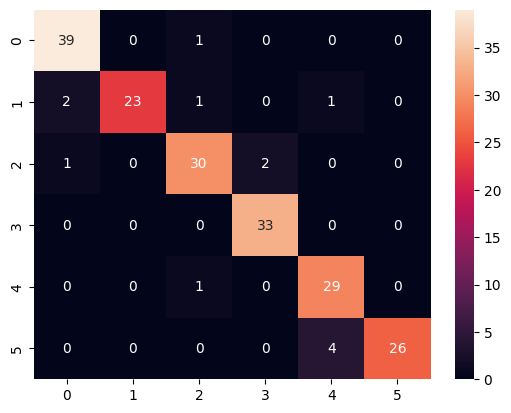

In [17]:
# 6. Convolutional Neural Network (1D for feature data)
X_train_cnn = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_cnn = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

cnn_model = Sequential([
    Conv1D(32, kernel_size=3, activation='relu', input_shape=(X_train.shape[1], 1)),
    MaxPooling1D(2),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(len(np.unique(y)), activation='softmax')
])
cnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn_model.fit(X_train_cnn, y_train, epochs=20, batch_size=16, verbose=0)
cnn_eval = cnn_model.evaluate(X_test_cnn, y_test)
y_pred_cnn = np.argmax(cnn_model.predict(X_test_cnn), axis=1)
evaluate_model(cnn_model, X_test_cnn, y_test)